In [55]:
import pandas as pd
import numpy as np

In [2]:
columns = ["tid","price","date","postcode","ptype","newbuild","tenure","paon","saon",
        "street","locality","town","district","county","cat","status"]

In [3]:
# read house price csv files
hp20 = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//pp-2020.csv", header=None, names=columns)
hp21 = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//pp-2021.csv", header=None, names=columns)
hp22 = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//pp-2022.csv", header=None, names=columns)
hp23 = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//pp-2023.csv", header=None, names=columns)
hp24 = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//pp-2024.csv", header=None, names=columns)


In [4]:
# merge house price csv files
merged_house_price = pd.concat([hp20, hp21, hp22, hp23, hp24], ignore_index=True)
merged_house_price.to_csv("merged_house_price_dataset.csv", index=False)

UNDERSTAND HOUSE PRICE DATASET

In [5]:
print("Shape:",merged_house_price.shape)
print("Number of Rows:", merged_house_price.shape[0])
print("Number of Columns:", merged_house_price.shape[1])
merged_house_price.head()

Shape: (5051767, 16)
Number of Rows: 5051767
Number of Columns: 16


,tid,price,date,postcode,ptype,newbuild,tenure,paon,saon,street,locality,town,district,county,cat,status
0,{BA558B33-0888-76EF-E053-6B04A8C0B4B7},193000,2020-11-02 00:00,IP27 9RD,T,N,F,17,NaN,CHESTNUT WAY,RAF LAKENHEATH,BRANDON,WEST SUFFOLK,SUFFOLK,A,A
1,{BA558B33-0889-76EF-E053-6B04A8C0B4B7},500000,2020-11-27 00:00,IP13 9FG,D,N,F,7,NaN,CLARKE DRIVE,FRAMLINGHAM,WOODBRIDGE,EAST SUFFOLK,SUFFOLK,A,A
2,{BA558B33-088C-76EF-E053-6B04A8C0B4B7},142000,2020-12-07 00:00,IP28 7JL,F,N,L,"THE OLD VICARAGE, 35",FLAT 7,QUEENSWAY,MILDENHALL,BURY ST EDMUNDS,WEST SUFFOLK,SUFFOLK,A,A
3,{BA558B33-088D-76EF-E053-6B04A8C0B4B7},142000,2020-11-27 00:00,IP33 3SH,F,N,L,22,NaN,PRINCE OF WALES CLOSE,NaN,BURY ST EDMUNDS,WEST SUFFOLK,SUFFOLK,A,A
4,{BA558B33-088E-76EF-E053-6B04A8C0B4B7},175000,2020-11-09 00:00,NR33 7HR,T,N,F,163,NaN,STRADBROKE ROAD,NaN,LOWESTOFT,EAST SUFFOLK,SUFFOLK,A,A


In [6]:
#column names
merged_house_price.columns

Index(['tid', 'price', 'date', 'postcode', 'ptype', 'newbuild', 'tenure',
       'paon', 'saon', 'street', 'locality', 'town', 'district', 'county',
       'cat', 'status'],
      dtype='object')

In [7]:
# dataset information
merged_house_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5051767 entries, 0 to 5051766
Data columns (total 16 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   tid       object
 1   price     int64 
 2   date      object
 3   postcode  object
 4   ptype     object
 5   newbuild  object
 6   tenure    object
 7   paon      object
 8   saon      object
 9   street    object
 10  locality  object
 11  town      object
 12  district  object
 13  county    object
 14  cat       object
 15  status    object
dtypes: int64(1), object(15)
memory usage: 616.7+ MB


In [8]:
# missing values
merged_house_price.isnull().sum()

tid               0
price             0
date              0
postcode      15041
ptype             0
newbuild          0
tenure            0
paon              0
saon        4377608
street        91364
locality    3114627
town              0
district          0
county            0
cat               0
status            0
dtype: int64

In [9]:
# duplicate values
print("Total Duplicates:", merged_house_price.duplicated().sum())

Total Duplicates: 0


In [10]:
# property type value count
# D = Detached, S = Semi-detached, T = Terraced, F = Flats, O = Other
print(merged_house_price["ptype"].value_counts())

ptype
T    1350259
S    1332221
D    1177023
F     897913
O     294351
Name: count, dtype: int64


In [11]:
# new build vs existing property value count
print(merged_house_price["newbuild"].value_counts())

newbuild
N    4482421
Y     569346
Name: count, dtype: int64


In [12]:
# freehold vs leasehold value count
print(merged_house_price["tenure"].value_counts())

tenure
F    3877597
L    1174170
Name: count, dtype: int64


In [13]:
# price paid category
print(merged_house_price["cat"].value_counts())

cat
A    4223493
B     828274
Name: count, dtype: int64


In [14]:
# top 10 counties by transactions
merged_house_price["county"].value_counts().head(10)

county
GREATER LONDON        567873
GREATER MANCHESTER    233836
WEST YORKSHIRE        193194
WEST MIDLANDS         185900
KENT                  145745
ESSEX                 136981
LANCASHIRE            124392
HAMPSHIRE             123965
MERSEYSIDE            119144
SOUTH YORKSHIRE       113953
Name: count, dtype: int64

In [15]:
# price distribution
merged_house_price["price"].describe()

count    5.051767e+06
mean     3.974039e+05
std      1.594294e+06
min      1.000000e+00
25%      1.730000e+05
50%      2.700000e+05
75%      4.175000e+05
max      9.000000e+08
Name: price, dtype: float64

In [16]:
# geographical columns
geo_columns = ["postcode", "locality", "town", "district", "county"]

for col in geo_columns:
    print("\n", col)
    print("Unique values:", merged_house_price[col].nunique())
    print(merged_house_price[col].value_counts().head(10))


 postcode
Unique values: 1083384
postcode
E14 9GU     449
CF10 3FH    405
LS7 1AW     290
WC2A 2AT    220
M4 4FZ      218
LS7 1NJ     217
SW1P 3AN    213
EC2A 2FJ    212
BD1 5AZ     207
E14 9ZW     195
Name: count, dtype: int64

 locality
Unique values: 20771
locality
MIDDLETON     5424
SHIRLEY       5108
WORSLEY       4486
KINGSWOOD     4224
HUCKNALL      3540
BROUGHTON     3523
BEESTON       3500
LONG EATON    3425
ECCLES        3417
URMSTON       3275
Name: count, dtype: int64

 town
Unique values: 1151
town
LONDON        347447
MANCHESTER     85586
BRISTOL        76346
BIRMINGHAM     69832
NOTTINGHAM     67103
LIVERPOOL      59950
LEEDS          56299
SHEFFIELD      49591
LEICESTER      40620
NORWICH        37804
Name: count, dtype: int64

 district
Unique values: 346
district
BIRMINGHAM                             68450
LEEDS                                  66340
CORNWALL                               57739
COUNTY DURHAM                          53110
BUCKINGHAMSHIRE            

In [17]:
# geographical coverage
print("Towns:", merged_house_price["town"].nunique())
print("Districts:", merged_house_price["district"].nunique())
print("Counties:", merged_house_price["county"].nunique())

Towns: 1151
Districts: 346
Counties: 115


CLEAN HOUSE PRICE DATASET

In [18]:
# duplicates
print("Duplicate rows:", merged_house_price.duplicated().sum())
merged_house_price.drop_duplicates(inplace=True)

Duplicate rows: 0


In [19]:
# clean text columns
text_columns = [
    "postcode", "ptype", "newbuild", "tenure",
    "paon", "saon", "street", "locality",
    "town", "district", "county", "cat", "status"
]

for col in text_columns:
    merged_house_price[col] = merged_house_price[col].str.strip()

In [20]:
# standardize geographical columns
geo_columns = ["postcode", "town", "district", "county", "locality"]

for col in geo_columns:
    merged_house_price[col] = merged_house_price[col].str.upper()

In [21]:
# convert data types
merged_house_price["price"] = pd.to_numeric(
    merged_house_price["price"], errors="coerce"
)

merged_house_price["date"] = pd.to_datetime(
    merged_house_price["date"], errors="coerce"
)

In [22]:
# check missing values
print("\nMissing Values:")
print(merged_house_price.isnull().sum())


Missing Values:
tid               0
price             0
date              0
postcode      15041
ptype             0
newbuild          0
tenure            0
paon              0
saon        4377608
street        91364
locality    3114627
town              0
district          0
county            0
cat               0
status            0
dtype: int64


In [23]:
# drop missing values 
merged_house_price.drop(columns=["postcode"], inplace=True)
merged_house_price.drop(columns=["saon"], inplace=True)
merged_house_price.drop(columns=["street"], inplace=True)
merged_house_price.drop(columns=["locality"], inplace=True)

In [24]:
print("Final Shape:", merged_house_price.shape)

Final Shape: (5051767, 12)


In [25]:
# cleaned dataset 
merged_house_price.to_csv("cleaned_house_price_dataset.csv", index=False)

In [26]:
# read income dataset
income = pd.read_csv("c://Users//USER//Desktop//Programming for Data Science//Project//Raw Datasets//gross-disposable-household-income-per-head.csv")
income.head()

,areacd,areanm,period,value
0,E06000001,Hartlepool,1997-01-01/P1Y,8273
1,E06000001,Hartlepool,1998-01-01/P1Y,8315
2,E06000001,Hartlepool,1999-01-01/P1Y,8799
3,E06000001,Hartlepool,2000-01-01/P1Y,9110
4,E06000001,Hartlepool,2001-01-01/P1Y,9558


UNDERSTAND INCOME DATASET

In [27]:
print(income.shape)
print(income.dtypes)

(17724, 4)
areacd    object
areanm    object
period    object
value      int64
dtype: object


In [28]:
# extract year
income["year"] = income["period"].str[:4].astype(int)

# find range
print("Years:", income["year"].min(), "to", income["year"].max())

# unique geographical areas
print("Number of areas:", income["areacd"].nunique())

Years: 1997 to 2024
Number of areas: 633


In [29]:
# statistical summary
income["value"].describe()

count     17724.000000
mean      17121.443297
std        8240.365254
min        5738.000000
25%       12737.750000
50%       15869.000000
75%       19692.250000
max      211245.000000
Name: value, dtype: float64

In [30]:
income["code_type"] = income["areacd"].str[:3]
income[income["year"] == 2024]["code_type"].value_counts()

code_type
E07    164
E06     63
E08     36
E09     33
S12     32
TLI     26
TLJ     26
TLM     24
TLH     24
TLD     23
W06     22
E10     21
TLK     17
TLG     16
TLL     15
E47     14
TLE     14
TLF     13
TLN     12
N09     11
E12      9
TLC      7
E13      2
E92      1
N92      1
N34      1
K03      1
K04      1
K02      1
S92      1
W42      1
W92      1
Name: count, dtype: int64

In [31]:
# count missing values
print(income.isna().sum())

# count duplicate rows
print("Duplicate rows:", income.duplicated().sum())

# count area code and year repeatation
print("Duplicate area-year pairs:", income.duplicated(["areacd", "year"]).sum())

# count 0 or neg values
print("Values <= 0:", (income["value"] <= 0).sum())

areacd       0
areanm       0
period       0
value        0
year         0
code_type    0
dtype: int64
Duplicate rows: 0
Duplicate area-year pairs: 0
Values <= 0: 0


CLEAN INCOME DATASET

In [32]:
# select geographical areas
la_codes = ["E06", "E07", "E08", "E09", "W06"]
income = income[income["code_type"].isin(la_codes)]
print(income["areacd"].nunique(), "areas kept")

318 areas kept


In [33]:
# keep 2020-2024 data
income = income[(income["year"] >= 2020) & (income["year"] <= 2024)]
print(income.shape)
print(income["year"].value_counts().sort_index())

(1590, 6)
year
2020    318
2021    318
2022    318
2023    318
2024    318
Name: count, dtype: int64


In [34]:
income = income.rename(columns={"value": "gdhi_per_head"})
income["area_key"] = income["areanm"].str.strip().str.upper()
income = income[["areacd", "areanm", "area_key", "year", "gdhi_per_head"]]
income.head()

,areacd,areanm,area_key,year,gdhi_per_head
23,E06000001,Hartlepool,HARTLEPOOL,2020,16455
24,E06000001,Hartlepool,HARTLEPOOL,2021,17292
25,E06000001,Hartlepool,HARTLEPOOL,2022,17957
26,E06000001,Hartlepool,HARTLEPOOL,2023,19095
27,E06000001,Hartlepool,HARTLEPOOL,2024,20080


In [35]:
print(income.groupby("areacd")["year"].count().value_counts())

year
5    318
Name: count, dtype: int64


In [36]:
# cleaned dataset
income.to_csv("cleaned_income_dataset.csv", index=False)
print(income.shape)

(1590, 5)


In [38]:
# geographical harmonization between house price and income
district_mapping = {
    'CITY OF BRISTOL': 'BRISTOL, CITY OF', 'CITY OF PLYMOUTH': 'PLYMOUTH', 'CITY OF KINGSTON UPON HULL': 'KINGSTON UPON HULL, CITY OF',
    'CITY OF NOTTINGHAM': 'NOTTINGHAM', 'CITY OF DERBY': 'DERBY', 'RHONDDA CYNON TAFF': 'RHONDDA CYNON TAF', 'CITY OF WESTMINSTER': 'WESTMINSTER',
    'CITY OF PETERBOROUGH': 'PETERBOROUGH', 'HEREFORDSHIRE': 'HEREFORDSHIRE, COUNTY OF', 'WREKIN': 'TELFORD AND WREKIN',
    'ST HELENS': 'ST. HELENS', 'THE VALE OF GLAMORGAN': 'VALE OF GLAMORGAN', 'AYLESBURY VALE': 'BUCKINGHAMSHIRE',
    'CHILTERN': 'BUCKINGHAMSHIRE', 'SOUTH BUCKS': 'BUCKINGHAMSHIRE', 'WYCOMBE': 'BUCKINGHAMSHIRE', 'CORBY': 'NORTH NORTHAMPTONSHIRE',
    'EAST NORTHAMPTONSHIRE': 'NORTH NORTHAMPTONSHIRE', 'KETTERING': 'NORTH NORTHAMPTONSHIRE', 'WELLINGBOROUGH': 'NORTH NORTHAMPTONSHIRE',
    'DAVENTRY': 'WEST NORTHAMPTONSHIRE', 'NORTHAMPTON': 'WEST NORTHAMPTONSHIRE', 'SOUTH NORTHAMPTONSHIRE': 'WEST NORTHAMPTONSHIRE',
    'CRAVEN': 'NORTH YORKSHIRE', 'HAMBLETON': 'NORTH YORKSHIRE', 'HARROGATE': 'NORTH YORKSHIRE', 'RICHMONDSHIRE': 'NORTH YORKSHIRE',
    'RYEDALE': 'NORTH YORKSHIRE', 'SCARBOROUGH': 'NORTH YORKSHIRE', 'SELBY': 'NORTH YORKSHIRE', 'ALLERDALE': 'CUMBERLAND',
    'CARLISLE': 'CUMBERLAND', 'COPELAND': 'CUMBERLAND', 'BARROW-IN-FURNESS': 'WESTMORLAND AND FURNESS', 'EDEN': 'WESTMORLAND AND FURNESS',
    'SOUTH LAKELAND': 'WESTMORLAND AND FURNESS', 'MENDIP': 'SOMERSET', 'SEDGEMOOR': 'SOMERSET', 'SOMERSET WEST AND TAUNTON': 'SOMERSET',
    'SOUTH SOMERSET': 'SOMERSET'
}

county_to_region = {
    # North East
    'COUNTY DURHAM': 'North East', 'DARLINGTON': 'North East', 'HARTLEPOOL': 'North East',
    'MIDDLESBROUGH': 'North East', 'NORTHUMBERLAND': 'North East', 'REDCAR AND CLEVELAND': 'North East',
    'STOCKTON-ON-TEES': 'North East', 'TYNE AND WEAR': 'North East',
    
    # North West
    'BLACKBURN WITH DARWEN': 'North West', 'BLACKPOOL': 'North West', 'CHESHIRE EAST': 'North West',
    'CHESHIRE WEST AND CHESTER': 'North West', 'CUMBERLAND': 'North West', 'CUMBRIA': 'North West',
    'GREATER MANCHESTER': 'North West', 'HALTON': 'North West', 'LANCASHIRE': 'North West',
    'MERSEYSIDE': 'North West', 'WARRINGTON': 'North West', 'WESTMORLAND AND FURNESS': 'North West',
    
    # Yorkshire and The Humber
    'CITY OF KINGSTON UPON HULL': 'Yorkshire and The Humber', 'EAST RIDING OF YORKSHIRE': 'Yorkshire and The Humber',
    'NORTH EAST LINCOLNSHIRE': 'Yorkshire and The Humber', 'NORTH LINCOLNSHIRE': 'Yorkshire and The Humber',
    'NORTH YORKSHIRE': 'Yorkshire and The Humber', 'SOUTH YORKSHIRE': 'Yorkshire and The Humber',
    'WEST YORKSHIRE': 'Yorkshire and The Humber', 'YORK': 'Yorkshire and The Humber',
    
    # East Midlands
    'CITY OF DERBY': 'East Midlands', 'CITY OF NOTTINGHAM': 'East Midlands', 'DERBYSHIRE': 'East Midlands',
    'LEICESTER': 'East Midlands', 'LEICESTERSHIRE': 'East Midlands', 'LINCOLNSHIRE': 'East Midlands',
    'NORTH NORTHAMPTONSHIRE': 'East Midlands', 'NORTHAMPTONSHIRE': 'East Midlands',
    'NOTTINGHAMSHIRE': 'East Midlands', 'RUTLAND': 'East Midlands', 'WEST NORTHAMPTONSHIRE': 'East Midlands',
    
    # West Midlands
    'HEREFORDSHIRE': 'West Midlands', 'SHROPSHIRE': 'West Midlands', 'STAFFORDSHIRE': 'West Midlands',
    'STOKE-ON-TRENT': 'West Midlands', 'TELFORD AND WREKIN': 'West Midlands', 'WARWICKSHIRE': 'West Midlands',
    'WEST MIDLANDS': 'West Midlands', 'WORCESTERSHIRE': 'West Midlands', 'WREKIN': 'West Midlands',
    
    # East of England
    'BEDFORD': 'East of England', 'CAMBRIDGESHIRE': 'East of England', 'CENTRAL BEDFORDSHIRE': 'East of England',
    'CITY OF PETERBOROUGH': 'East of England', 'ESSEX': 'East of England', 'HERTFORDSHIRE': 'East of England',
    'LUTON': 'East of England', 'NORFOLK': 'East of England', 'SOUTHEND-ON-SEA': 'East of England',
    'SUFFOLK': 'East of England', 'THURROCK': 'East of England',
    
    # London
    'GREATER LONDON': 'London',
    
    # South East
    'BRACKNELL FOREST': 'South East', 'BRIGHTON AND HOVE': 'South East', 'BUCKINGHAMSHIRE': 'South East',
    'EAST SUSSEX': 'South East', 'HAMPSHIRE': 'South East', 'ISLE OF WIGHT': 'South East', 'KENT': 'South East',
    'MEDWAY': 'South East', 'MILTON KEYNES': 'South East', 'OXFORDSHIRE': 'South East',
    'PORTSMOUTH': 'South East', 'READING': 'South East', 'SLOUGH': 'South East',
    'SOUTHAMPTON': 'South East', 'SURREY': 'South East', 'WEST BERKSHIRE': 'South East',
    'WEST SUSSEX': 'South East', 'WINDSOR AND MAIDENHEAD': 'South East', 'WOKINGHAM': 'South East',
    
    # South West
    'BATH AND NORTH EAST SOMERSET': 'South West', 'BOURNEMOUTH, CHRISTCHURCH AND POOLE': 'South West',
    'CITY OF BRISTOL': 'South West', 'CITY OF PLYMOUTH': 'South West', 'CORNWALL': 'South West',
    'DEVON': 'South West', 'DORSET': 'South West', 'GLOUCESTERSHIRE': 'South West',
    'ISLES OF SCILLY': 'South West', 'NORTH SOMERSET': 'South West', 'SOMERSET': 'South West',
    'SOUTH GLOUCESTERSHIRE': 'South West', 'SWINDON': 'South West', 'TORBAY': 'South West', 'WILTSHIRE': 'South West',
    
    # Wales
    'BLAENAU GWENT': 'Wales', 'BRIDGEND': 'Wales', 'CAERPHILLY': 'Wales', 'CARDIFF': 'Wales',
    'CARMARTHENSHIRE': 'Wales', 'CEREDIGION': 'Wales', 'CONWY': 'Wales', 'DENBIGHSHIRE': 'Wales',
    'FLINTSHIRE': 'Wales', 'GWYNEDD': 'Wales', 'ISLE OF ANGLESEY': 'Wales', 'MERTHYR TYDFIL': 'Wales',
    'MONMOUTHSHIRE': 'Wales', 'NEATH PORT TALBOT': 'Wales', 'NEWPORT': 'Wales', 'PEMBROKESHIRE': 'Wales',
    'POWYS': 'Wales', 'RHONDDA CYNON TAFF': 'Wales', 'SWANSEA': 'Wales', 'THE VALE OF GLAMORGAN': 'Wales',
    'TORFAEN': 'Wales', 'WREXHAM': 'Wales'
}

# apply mappings to house price data
merged_house_price['year'] = merged_house_price['date'].dt.year
merged_house_price['area_key'] = merged_house_price['district'].replace(district_mapping)
merged_house_price['region'] = merged_house_price['county'].replace(county_to_region)


In [39]:
# feature engineering to calculate annual housing affordability 

# group house price by area and year
la_annual = merged_house_price.groupby(['area_key', 'year']).agg(
    median_price=('price', 'median'),
    mean_price=('price', 'mean'),
    std_price=('price', 'std'),
    q25_price=('price', lambda x: x.quantile(0.25)),
    q75_price=('price', lambda x: x.quantile(0.75)),
    sales_count=('price', 'count'),
    region=('region', lambda x: x.mode()[0])
).reset_index()

# merge with income dataset
la_affordability = pd.merge(la_annual, income[['areacd', 'areanm', 'area_key', 'year', 'gdhi_per_head']], on=['area_key', 'year'])
# calculate affordability
# affordability Ratio = median House Price / GDHI per Head
la_affordability['affordability_ratio'] = la_affordability['median_price'] / la_affordability['gdhi_per_head']

# Save harmonized aggregated dataset
la_affordability.to_csv('la_annual_affordability.csv', index=False)
print("Harmonized Local Authority Affordability Dataset:")
print("Rows:", len(la_affordability))
print("Local Authorities:", la_affordability['areanm'].nunique())
print("Years:", sorted(la_affordability['year'].unique()))
la_affordability[['areanm', 'region', 'year', 'median_price', 'gdhi_per_head', 'affordability_ratio']].head(10)

Harmonized Local Authority Affordability Dataset:
Rows: 1590
Local Authorities: 318
Years: [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


,areanm,region,year,median_price,gdhi_per_head,affordability_ratio
0,Adur,South East,2020,320000.0,19829,16.137980
1,Adur,South East,2021,353000.0,20808,16.964629
2,Adur,South East,2022,380000.0,21935,17.323912
3,Adur,South East,2023,375000.0,23663,15.847526
4,Adur,South East,2024,364000.0,25237,14.423267
5,Amber Valley,East Midlands,2020,179475.0,19344,9.278071
6,Amber Valley,East Midlands,2021,209950.0,19901,10.549721
7,Amber Valley,East Midlands,2022,217500.0,20779,10.467299
8,Amber Valley,East Midlands,2023,223375.0,22507,9.924690
9,Amber Valley,East Midlands,2024,225000.0,24016,9.368754


EDA AND SUMMARY STATISTICS

In [45]:
summary_stats = pd.DataFrame({
    'Metric': ['Count', 'Mean', 'Std Dev', 'Min', '25% (Q1)', '50% (Median)', '75% (Q3)', 'Max', 'Skewness'],

    'Transaction Price (£)': [
        "{:,}".format(merged_house_price['price'].count()),
        "£" + str(round(merged_house_price['price'].mean())),
        "£" + str(round(merged_house_price['price'].std())),
        "£" + str(round(merged_house_price['price'].min())),
        "£" + str(round(merged_house_price['price'].quantile(0.25))),
        "£" + str(round(merged_house_price['price'].median())),
        "£" + str(round(merged_house_price['price'].quantile(0.75))),
        "£" + str(round(merged_house_price['price'].max())),
        round(merged_house_price['price'].skew(), 2)
    ],

    'GDHI Per Head (£)': [
        "{:,}".format(la_affordability['gdhi_per_head'].count()),
        "£" + str(round(la_affordability['gdhi_per_head'].mean())),
        "£" + str(round(la_affordability['gdhi_per_head'].std())),
        "£" + str(round(la_affordability['gdhi_per_head'].min())),
        "£" + str(round(la_affordability['gdhi_per_head'].quantile(0.25))),
        "£" + str(round(la_affordability['gdhi_per_head'].median())),
        "£" + str(round(la_affordability['gdhi_per_head'].quantile(0.75))),
        "£" + str(round(la_affordability['gdhi_per_head'].max())),
        round(la_affordability['gdhi_per_head'].skew(), 2)
    ],

    'Affordability Ratio': [
        "{:,}".format(la_affordability['affordability_ratio'].count()),
        str(round(la_affordability['affordability_ratio'].mean(), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].std(), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].min(), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].quantile(0.25), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].median(), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].quantile(0.75), 2)) + "x",
        str(round(la_affordability['affordability_ratio'].max(), 2)) + "x",
        round(la_affordability['affordability_ratio'].skew(), 2)
    ]
})

summary_stats

,Metric,Transaction Price (£),GDHI Per Head (£),Affordability Ratio
0,Count,"5,051,767","1,590","1,590"
1,Mean,£397404,£24184,12.33x
2,Std Dev,£1594294,£10403,2.91x
3,Min,£1,£13909,4.9x
4,25% (Q1),£173000,£19372,10.11x
5,50% (Median),£270000,£22180,12.32x
6,75% (Q3),£417500,£26161,14.37x
7,Max,£900000000,£171569,21.44x
8,Skewness,124.98,7.24,0.17


RESEARCH QUESTION 1: How did median house prices and GDHI per head each change between 2020 and 2024, and which grew faster?

In [ ]:
overall_hp = merged_house_price.groupby('year')['price'].agg(median_price='median', mean_price='mean', sales_count='count').reset_index()
overall_inc = income.groupby('year')['gdhi_per_head'].agg(median_income='median', mean_income='mean').reset_index()

# merge annual house price and annual income
rq1_table = pd.merge(overall_hp, overall_inc, on='year')
# affordability ratio
rq1_table['affordability_ratio'] = rq1_table['median_price'] / rq1_table['median_income']
# calculate annual house price growth
rq1_table['price_growth_%'] = rq1_table['median_price'].pct_change() * 100
# calculate annual income growth
rq1_table['income_growth_%'] = rq1_table['median_income'].pct_change() * 100

print("Annual Summary (2020-2024)")
print(rq1_table[['year', 'median_price', 'price_growth_%', 'median_income', 'income_growth_%', 'affordability_ratio']])

# 2020 vs 2024 omparison
p20, p24 = rq1_table.loc[rq1_table['year']==2020, 'median_price'].values[0], rq1_table.loc[rq1_table['year']==2024, 'median_price'].values[0]
i20, i24 = rq1_table.loc[rq1_table['year']==2020, 'median_income'].values[0], rq1_table.loc[rq1_table['year']==2024, 'median_income'].values[0]

print("Cumulative Growth (2020 to 2024)")
price_growth = ((p24 - p20) / p20) * 100
income_growth = ((i24 - i20) / i20) * 100

print("Median House Price: £" + str(round(p20)) + " -> £" + str(round(p24)) +
      " | Total Growth: " + str(round(price_growth, 2)) + "%")

print("Median GDHI/Head: £" + str(round(i20)) + " -> £" + str(round(i24)) +
      " | Total Growth: " + str(round(income_growth, 2)) + "%")

Annual Summary (2020-2024)
   year  median_price  price_growth_%  median_income  income_growth_%  \
0  2020      249995.0             NaN        20226.0              NaN   
1  2021      269995.0        8.000160        20985.5         3.755068   
2  2022      280000.0        3.705624        21973.5         4.708013   
3  2023      275000.0       -1.785714        23486.5         6.885567   
4  2024      280000.0        1.818182        25007.5         6.476061   

   affordability_ratio  
0            12.360081  
1            12.865788  
2            12.742622  
3            11.708854  
4            11.196641  
Cumulative Growth (2020 to 2024)
Median House Price: £249995 -> £280000 | Total Growth: 12.0%
Median GDHI/Head: £20226 -> £25008 | Total Growth: 23.64%


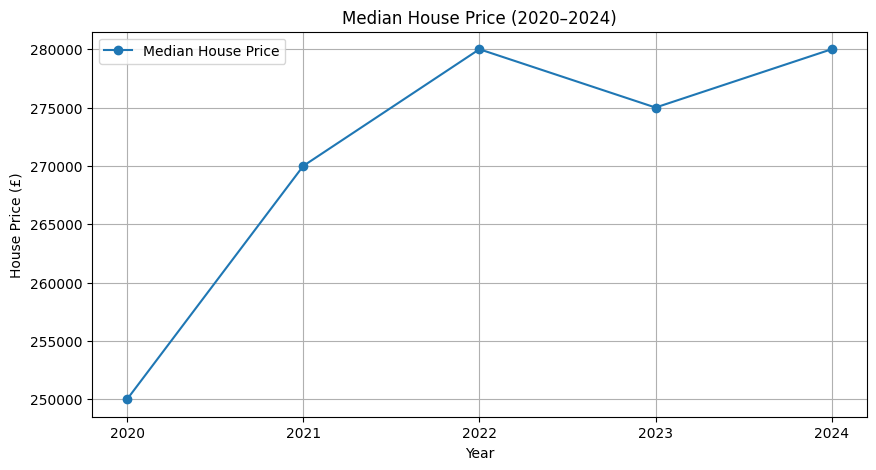

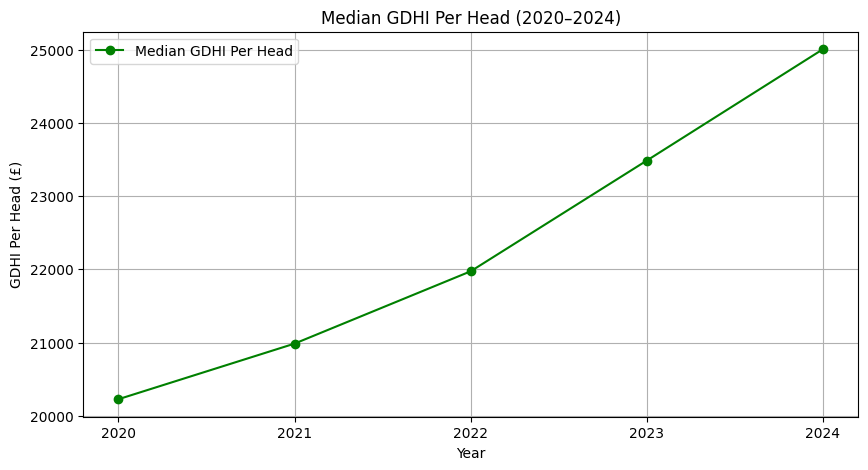

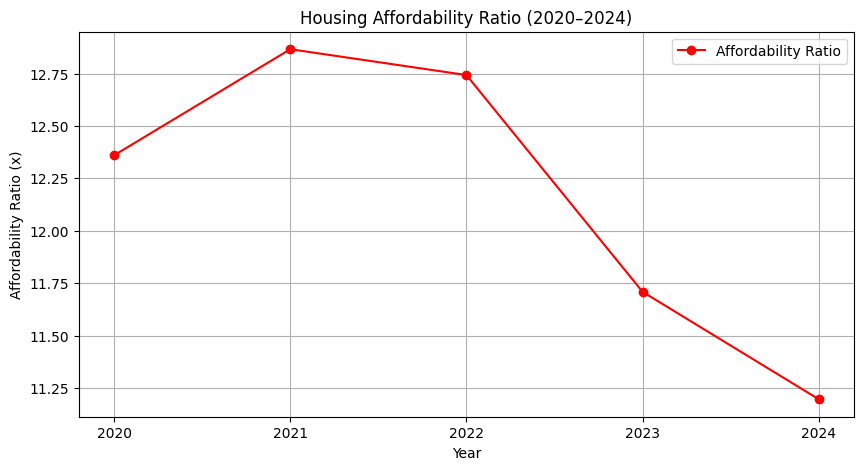

In [49]:
import matplotlib.pyplot as plt

# median house price
plt.figure(figsize=(10, 5))
plt.plot(rq1_table['year'], rq1_table['median_price'], marker='o', label='Median House Price')
plt.title('Median House Price (2020–2024)')
plt.xlabel('Year')
plt.ylabel('House Price (£)')
plt.xticks(rq1_table['year'])
plt.grid(True)
plt.legend()
plt.show()

# median GDHI per head
plt.figure(figsize=(10, 5))
plt.plot(rq1_table['year'], rq1_table['median_income'], marker='o', color='green', label='Median GDHI Per Head')
plt.title('Median GDHI Per Head (2020–2024)')
plt.xlabel('Year')
plt.ylabel('GDHI Per Head (£)')
plt.xticks(rq1_table['year'])
plt.grid(True)
plt.legend()
plt.show()


# affordability over the years
plt.figure(figsize=(10, 5))
plt.plot(rq1_table['year'], rq1_table['affordability_ratio'], marker='o', color='red', label='Affordability Ratio')
plt.title('Housing Affordability Ratio (2020–2024)')
plt.xlabel('Year')
plt.ylabel('Affordability Ratio (x)')
plt.xticks(rq1_table['year'])
plt.grid(True)
plt.legend()
plt.show()

RESEARCH QUESTION 2: Which local authorities and regions are the least and most affordable, and did the gap between them widen?

In [53]:
# regional affordability ranking (2024 vs 2020)
reg_comp = la_affordability[la_affordability['year'].isin([2020, 2024])].groupby(['region', 'year']).agg(
    median_price=('median_price', 'median'),
    median_income=('gdhi_per_head', 'median'),
    median_ratio=('affordability_ratio', 'median')).reset_index()

# separate 2020 and 2024 column
reg_pivot = reg_comp.pivot(index='region', columns='year', values='median_ratio').reset_index()
# calculate change
reg_pivot['ratio_change'] = reg_pivot[2024] - reg_pivot[2020]
reg_pivot = reg_pivot.sort_values(2024, ascending=False)
print("Regional Affordability Comparison (2020 vs 2024)")
print(reg_pivot.to_string(index=False))

# least and most affordable areas in 2024
la24 = la_affordability[la_affordability['year'] == 2024]
top5_least = la24.sort_values('affordability_ratio', ascending=False)[['areanm', 'region', 'median_price', 'gdhi_per_head', 'affordability_ratio']].head(5)
top5_most = la24.sort_values('affordability_ratio', ascending=True)[['areanm', 'region', 'median_price', 'gdhi_per_head', 'affordability_ratio']].head(5)
print("Top 5 least affordable areas (2024)")
print(top5_least.to_string(index=False))
print("Top 5 most affordable areas (2024)")
print(top5_most.to_string(index=False))

# affordability gap evolution
gap_analysis = la_affordability.groupby('year').agg(
    min_ratio=('affordability_ratio', 'min'),
    p10_ratio=('affordability_ratio', lambda x: x.quantile(0.10)),
    median_ratio=('affordability_ratio', 'median'),
    p90_ratio=('affordability_ratio', lambda x: x.quantile(0.90)),
    max_ratio=('affordability_ratio', 'max')
).reset_index()

gap_analysis['extreme_spread (Max - Min)'] = gap_analysis['max_ratio'] - gap_analysis['min_ratio']
print("Affordability gap evolution (2020-2024)")
print(gap_analysis[['year', 'min_ratio', 'median_ratio', 'max_ratio', 'extreme_spread (Max - Min)']])


Regional Affordability Comparison (2020 vs 2024)
                  region      2020      2024  ratio_change
                  London 17.932135 15.230516     -2.701619
         East of England 14.533259 13.279037     -1.254222
              South East 14.498699 12.820642     -1.678057
              South West 13.037101 11.848754     -1.188347
           West Midlands 11.431115 10.877299     -0.553816
           East Midlands 10.640247 10.177542     -0.462706
                   Wales  9.484274  9.222702     -0.261572
              North West  9.047448  9.035974     -0.011473
Yorkshire and The Humber  8.971156  8.796352     -0.174804
              North East  7.939404  7.503348     -0.436056
Top 5 least affordable areas (2024)
        areanm          region  median_price  gdhi_per_head  affordability_ratio
    Hillingdon          London      480000.0          25875            18.550725
        Newham          London      435000.0          24514            17.744962
     Cambridge East of 

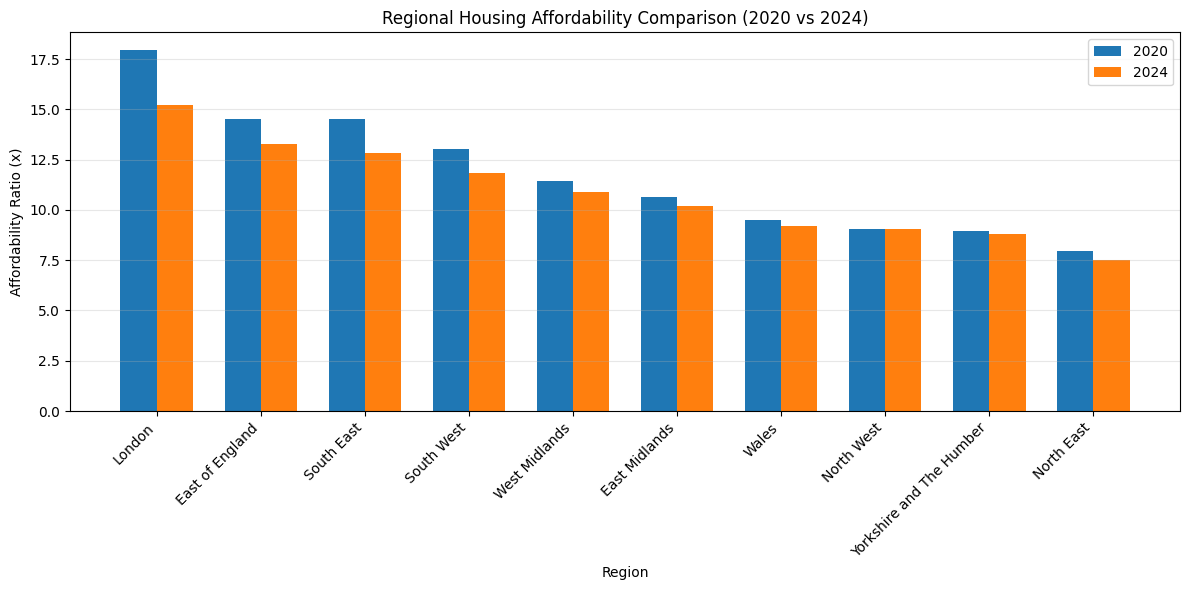

In [56]:
# regional affordability comparison (2020 vs 2024)
plt.figure(figsize=(12, 6))
x = np.arange(len(reg_pivot['region']))
width = 0.35
plt.bar(x - width/2, reg_pivot[2020], width, label='2020')
plt.bar(x + width/2, reg_pivot[2024], width, label='2024')
plt.title('Regional Housing Affordability Comparison (2020 vs 2024)')
plt.xlabel('Region')
plt.ylabel('Affordability Ratio (x)')
plt.xticks(x, reg_pivot['region'], rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

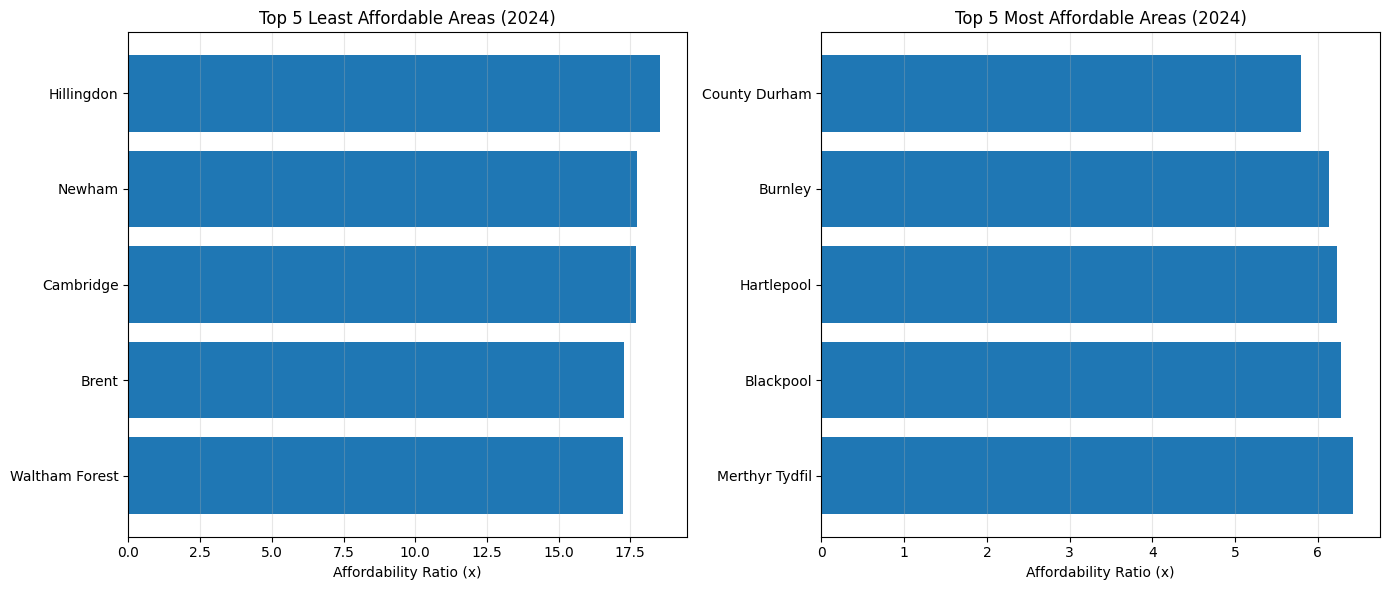

In [57]:
# top 5 least and most affordable local areas in 2024
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# least affordable
axes[0].barh(top5_least['areanm'], top5_least['affordability_ratio'])
axes[0].set_title('Top 5 Least Affordable Areas (2024)')
axes[0].set_xlabel('Affordability Ratio (x)')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# most affordable
axes[1].barh(top5_most['areanm'], top5_most['affordability_ratio'])
axes[1].set_title('Top 5 Most Affordable Areas (2024)')
axes[1].set_xlabel('Affordability Ratio (x)')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

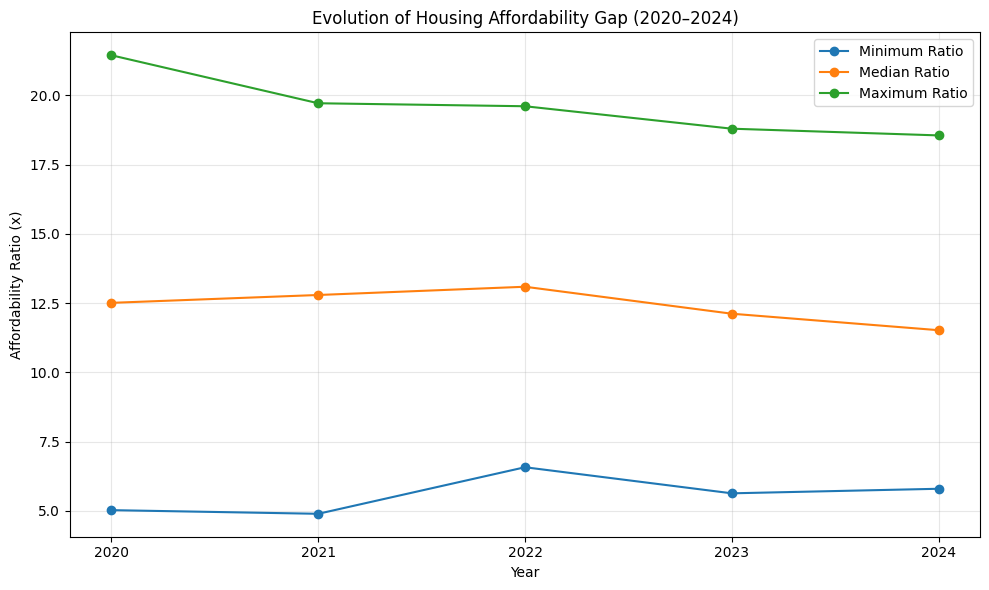

In [58]:
# affordability gap evolution (2020–2024)
plt.figure(figsize=(10, 6))
plt.plot(gap_analysis['year'], gap_analysis['min_ratio'], marker='o', label='Minimum Ratio')
plt.plot(gap_analysis['year'], gap_analysis['median_ratio'], marker='o', label='Median Ratio')
plt.plot(gap_analysis['year'], gap_analysis['max_ratio'], marker='o', label='Maximum Ratio')

plt.title('Evolution of Housing Affordability Gap (2020–2024)')
plt.xlabel('Year')
plt.ylabel('Affordability Ratio (x)')
plt.xticks(gap_analysis['year'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

RESEARCH QUESTION 3: How strongly is local income associated with median house price, and did this relationship change over the period?

In [60]:
# Correlation and Regression Analysis: GDHI per Head vs Median House Price (2020-2024)
corr_records = []
for yr in sorted(la_affordability['year'].unique()):
    sub = la_affordability[la_affordability['year'] == yr]
    r_pearson = sub['gdhi_per_head'].corr(sub['median_price'])
    rho_spearman = sub['gdhi_per_head'].corr(sub['median_price'], method='spearman')
    r2 = r_pearson ** 2
    corr_records.append({
        'Year': yr,
        'Pearson r': round(r_pearson, 3),
        'R² (Variance Explained)': round(r2, 3)
    })

rq3_df = pd.DataFrame(corr_records)
print("Local Income vs House Price Correlation (2020-2024)")
print(rq3_df.to_string(index=False))

Local Income vs House Price Correlation (2020-2024)
 Year  Pearson r  R² (Variance Explained)
 2020      0.728                    0.530
 2021      0.742                    0.550
 2022      0.835                    0.697
 2023      0.873                    0.762
 2024      0.883                    0.779


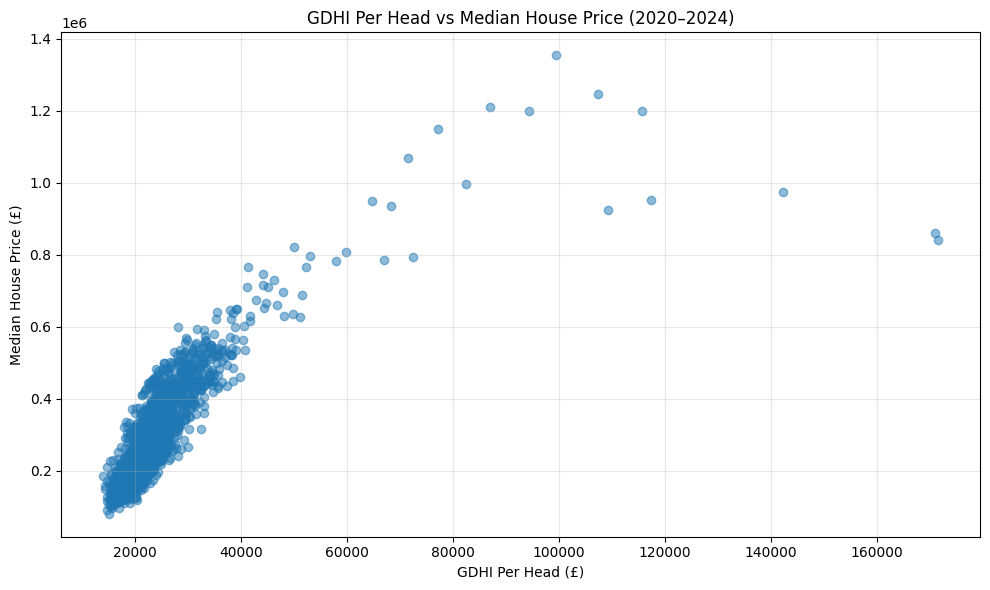

In [62]:
plt.figure(figsize=(10, 6))

plt.scatter(
    la_affordability['gdhi_per_head'],
    la_affordability['median_price'],
    alpha=0.5
)

plt.title('GDHI Per Head vs Median House Price (2020–2024)')
plt.xlabel('GDHI Per Head (£)')
plt.ylabel('Median House Price (£)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

RESEARCH QUESTION 4: Does affordability differ by property type (detached, semi-detached, terraced, flat)?

In [63]:
# affordability metrics by property type (2020-2024)
pt_data = pd.read_csv('property_type_affordability.csv')
pt_labels = {'D': 'Detached', 'S': 'Semi-detached', 'T': 'Terraced', 'F': 'Flat / Maisonette', 'O': 'Other'}
pt_data['Property Type'] = pt_data['ptype'].map(pt_labels)

pt_2024 = pt_data[pt_data['year'] == 2024].sort_values('median_price', ascending=False)
# compare each propert type with a terraced house
pt_2024['Price Premium vs Terraced (%)'] = ((pt_2024['median_price'] - 220000) / 220000) * 100
print("Affordability According to Property Type (2024)")
print(pt_2024[['Property Type', 'median_price', 'affordability_ratio', 'sales_count', 'Price Premium vs Terraced (%)']].to_string(index=False))

# across all years
pt_pivot = pt_data.pivot(index='Property Type', columns='year', values='affordability_ratio').reset_index()
print("Affordability Ratio Trajectory by Property Type (2020-2024)")
print(pt_pivot.to_string(index=False))

Affordability According to Property Type (2024)
    Property Type  median_price  affordability_ratio  sales_count  Price Premium vs Terraced (%)
         Detached      410000.0            16.395081       211537                      86.363636
            Other      300000.0            11.996401        54173                      36.363636
    Semi-detached      262500.0            10.496851       252254                      19.318182
Flat / Maisonette      237500.0             9.497151       164027                       7.954545
         Terraced      220000.0             8.797361       250223                       0.000000
Affordability Ratio Trajectory by Property Type (2020-2024)
    Property Type      2020      2021      2022      2023      2024
         Detached 17.699990 18.429392 19.113933 17.754880 16.395081
Flat / Maisonette 10.907891 10.959949 10.728923  9.835437  9.497151
            Other 12.299960 13.819066 13.652809 12.517829 11.996401
    Semi-detached 11.124295 11.674490 

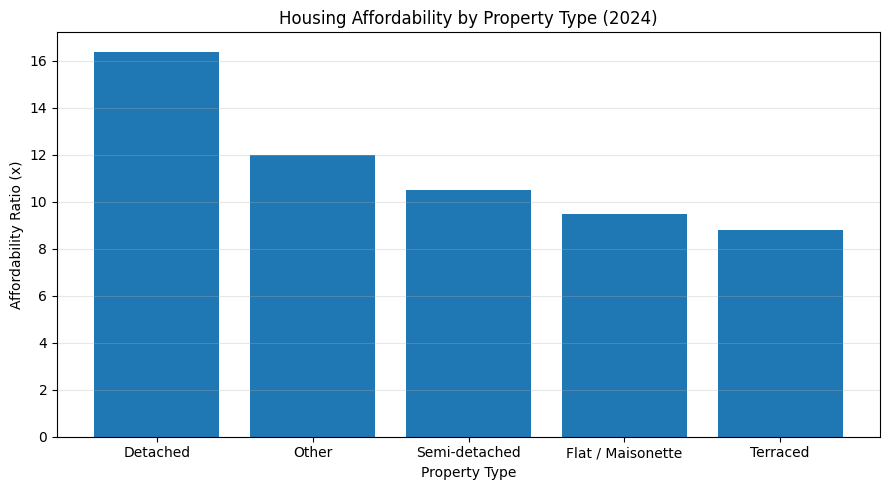

In [64]:
plt.figure(figsize=(9, 5))

plt.bar(
    pt_2024['Property Type'],
    pt_2024['affordability_ratio']
)

plt.title('Housing Affordability by Property Type (2024)')
plt.xlabel('Property Type')
plt.ylabel('Affordability Ratio (x)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

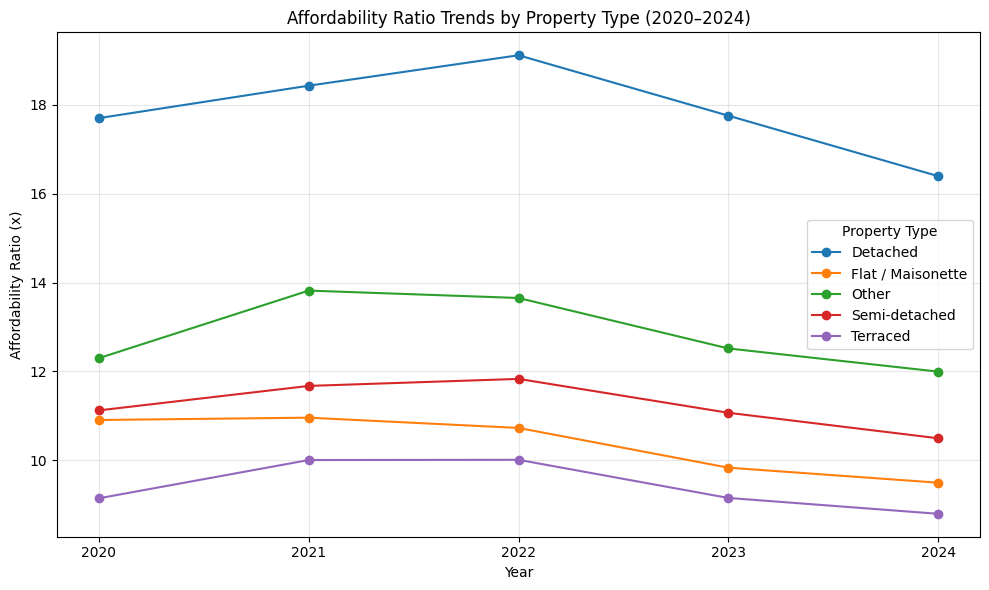

In [65]:
plt.figure(figsize=(10, 6))

for property_type in pt_pivot['Property Type']:
    row = pt_pivot[pt_pivot['Property Type'] == property_type]

    years = [2020, 2021, 2022, 2023, 2024]
    ratios = row[years].values.flatten()

    plt.plot(years, ratios, marker='o', label=property_type)

plt.title('Affordability Ratio Trends by Property Type (2020–2024)')
plt.xlabel('Year')
plt.ylabel('Affordability Ratio (x)')

plt.xticks([2020, 2021, 2022, 2023, 2024])
plt.legend(title='Property Type')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

RESEARCH QUESTION 5: How did prices and transaction volumes respond around 2020 to 2021 compared with 2022 to 2024?

In [66]:
# Shock Response Comparison: 2020-2021 vs 2022-2024
shock_data = pd.DataFrame({
    'Period': ['2020-2021', '2022-2024'], 'Economic Condition': ['Pandemic Stimulus Boom', 'Monetary Tightening Era'],
    'BoE Base Rate': ['0.10%', '0.10% to 5.25%'], 'Starting Median Price': [249995, 280000], 'Ending Median Price': [269995, 280000],
    'Price Growth (%)': [8.00, 0.00], 'Starting Sales': [898194, 1077406], 'Ending Sales': [1282171, 932214], 'Sales Growth (%)': [42.75, -13.48]
})

print("2020-2021 vs 2022-2024")
print(shock_data.to_string(index=False))

2020-2021 vs 2022-2024
   Period      Economic Condition  BoE Base Rate  Starting Median Price  Ending Median Price  Price Growth (%)  Starting Sales  Ending Sales  Sales Growth (%)
2020-2021  Pandemic Stimulus Boom          0.10%                 249995               269995               8.0          898194       1282171             42.75
2022-2024 Monetary Tightening Era 0.10% to 5.25%                 280000               280000               0.0         1077406        932214            -13.48


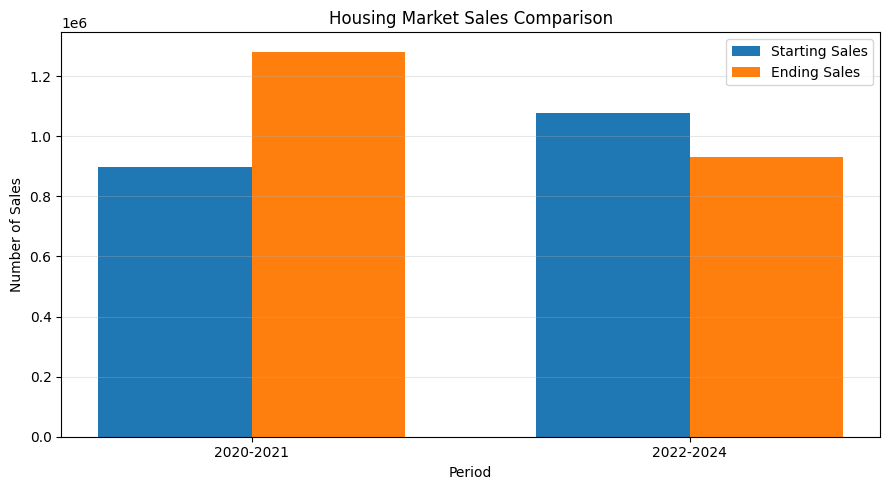

In [69]:
x = np.arange(len(shock_data['Period']))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, shock_data['Starting Sales'], width, label='Starting Sales')
plt.bar(x + width/2, shock_data['Ending Sales'], width, label='Ending Sales')

plt.title('Housing Market Sales Comparison')
plt.xlabel('Period')
plt.ylabel('Number of Sales')
plt.xticks(x, shock_data['Period'])
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()